# Clamped and face-clamped edges

This example compares two ways of clamping a thick plate: the clamp of the boundary condition flags and a clamp by the faces of the edge, imposed with prescribed displacements. It shows the warping of the section that the face clamp allows in the third-order shear deformation theory.

In the classical laminated plate theory (CLPT), a clamped edge $x = 0$ has $u = v = w = 0$ and $w_{,x} = 0$. In the first-order shear deformation theory (FSDT), the rotations $\phi_x$, $\phi_y$ replace the slope. The third-order theory (TSDT) of Reddy (1984) has the in-plane displacements

$$
u(z) = u_0 + z\phi_x - c_1 z^3 (\phi_x + w_{,x}), \qquad c_1 = \frac{4}{3h^2},
$$

about the mid-surface. With the flags, a clamped TSDT edge has `x1wr = 0` together with `x1phix = x1phiy = 0`, so the cross-section stays planar and unrotated. An edge clamped by its faces has $u = v = 0$ at $z = d \mp h/2$ and $w = 0$, where $d$ is the offset of the mid-surface from the reference surface. This leaves the section free to warp. It is prescribed with the keyword `z` of `Shell.add_distr_pd_fixed_x`, see [Boundary conditions](../boundary_conditions.rst).

The square plates below, $a = b = 0.5$ m, $h = 0.05$ m ($h/a = 0.1$), $E = 70$ GPa, $\nu = 0.3$, are clamped or simply supported at $x = 0, a$, free at $y = 0, b$, and loaded by a uniform pressure $q = 1$ MPa. The prescribed displacements are imposed exactly by a `MultiDomain` with `pd_method='null-space'`. The thin-plate limits are checked against the solutions of Timoshenko and Woinowsky-Krieger (1959), and the thick plate shows the effect of the transverse shear deformation on each support.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import solve
from structsolve.sparseutils import finalize_symmetric_matrix
from panels.shell import Shell
from panels.multidomain import MultiDomain
from panels.multidomain.connections import fkCld_xcte


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Model

`plate` builds a plate of thickness `h` with all edges free and the pressure load; $m = 26$ terms along $x$ resolve the boundary layer of the face clamp, see the convergence study below. `clamp_by_flags` constrains all the fields at an edge and, except for the FSDT, the slope of $w$. `simple_support` constrains $u = v = w = \phi_y = 0$ at the edges $x = 0, a$. `face_clamp` prescribes $u = v = 0$ at the two faces of the edge $x$ and $w = 0$. `fields` evaluates the displacements, the rotations and the transverse shear strains at given points, and `uv_at` the in-plane displacements at a thickness coordinate $z$ with the kinematics above.

In [2]:
A = B = 0.5
H = 0.05
E, NU = 70e9, 0.3
Q = 1e6
D = E*H**3/(12*(1 - NU**2))


def bending_stiffness(h):
    return E*h**3/(12*(1 - NU**2))
FIELDS = ('u', 'v', 'w', 'phix', 'phiy')


def plate(model, offset=0., m=26, n=10, h=H):
    s = Shell(model=model, a=A, b=B, stack=[0.], plyt=h, laminaprop=(E, NU),
              offset=offset, m=m, n=n)
    for edge in ('x1', 'x2', 'y1', 'y2'):
        for field in FIELDS:
            setattr(s, edge + field, 1.)
            setattr(s, edge + field + 'r', 1.)
    s.add_pressure_load(Q)
    return s


def clamp_by_flags(s, edge):
    for field in FIELDS:
        setattr(s, edge + field, 0.)
    if 'fsdt' not in s.model:
        setattr(s, edge + 'wr', 0.)


def simple_support(s):
    for edge in ('x1', 'x2'):
        for field in ('u', 'v', 'w', 'phiy'):
            setattr(s, edge + field, 0.)


def face_clamp(s, x, k=1., cte=True):
    zero = lambda y: 0.
    for z in (s.offset - s.plyt/2, s.offset + s.plyt/2):
        s.add_distr_pd_fixed_x(x, ku=k, kv=k, funcu=zero, funcv=zero, z=z,
                               cte=cte)
    s.add_distr_pd_fixed_x(x, kw=k, funcw=zero, cte=cte)


def static(s, pd_method='null-space'):
    md = MultiDomain([s], conn=[], pd_method=pd_method)
    return md.linear_static()


def fields(s, c, xs, ys):
    xs = np.atleast_1d(np.asarray(xs, dtype=float))
    ys = np.atleast_1d(np.asarray(ys, dtype=float))
    s.uvw(c, xs=xs, ys=ys)
    out = {k: s.fields[k].ravel().copy() for k in FIELDS}
    if 'clpt' in s.model:
        out['gxz'] = out['gyz'] = 0*out['u']
    else:
        s.strain(c, xs=xs, ys=ys, NLgeom=False)
        out['gxz'] = s.fields['gxz'].ravel().copy()
        out['gyz'] = s.fields['gyz'].ravel().copy()
    return out


def uv_at(s, f, z):
    c1 = 4/(3*s.plyt**2) if 'tsdt' in s.model else 0.
    d = s.offset
    p = -c1*((z - d)**3 + d**3)
    return (f['u'] + z*f['phix'] + p*f['gxz'],
            f['v'] + z*f['phiy'] + p*f['gyz'])


xs, ys = [g.ravel() for g in np.meshgrid(np.linspace(0, A, 7),
                                          np.linspace(0, B, 5))]

## CLPT and FSDT: the face clamp is the clamp of the flags

In these theories the displacements are linear in $z$. Zero displacements at both faces then mean zero displacement and zero rotation of the whole section, so the face clamp and the clamp of the flags give the same solution.

In [3]:
for model in ['plate_clpt_donnell', 'plate_fsdt_donnell']:
    s = plate(model)
    for x in (0., A):
        face_clamp(s, x)
    c = static(s)
    t = plate(model)
    clamp_by_flags(t, 'x1')
    clamp_by_flags(t, 'x2')
    ct = static(t)
    f, ft = fields(s, c, xs, ys), fields(t, ct, xs, ys)
    diff = max(np.abs(f[k] - ft[k]).max() for k in FIELDS)
    print('%-20s largest difference of the fields: %.1e of the largest w'
          % (model, diff/np.abs(ft['w']).max()))

plate_clpt_donnell   largest difference of the fields: 0.0e+00 of the largest w


plate_fsdt_donnell   largest difference of the fields: 0.0e+00 of the largest w


## Thin plate: comparison with the classical solutions

For the thin plate the CLPT applies. Timoshenko and Woinowsky-Krieger (1959) give, in Table 47 (Art. 48, p. 219), the deflections of a uniformly loaded rectangular plate with the edges $x = 0, a$ simply supported and the other two free, for $\nu = 0.3$: for the square plate, $w = 0.01309\, q a^4/D$ at the center and $w = 0.01509\, q a^4/D$ at the middle of the free edges.

For the edges $x = 0, a$ clamped and the others free they give no table. The reference is the cylindrical bending of an infinitely long plate with built-in edges (Art. 3, Eq. (18), p. 15),

$$
w_{max} = \frac{q a^4}{384 D} f_1(u), \qquad f_1(u) = \frac{24}{u^4}\left(\frac{u^2}{2} + \frac{u}{\sinh u} - \frac{u}{\tanh u}\right),
$$

where $u$ grows with the axial force; without axial force, as in the linear analysis here, $u \to 0$ and $f_1 \to 1$. The square plate with free edges is not in cylindrical bending: the anticlastic curvature makes the deflection vary along $y$. For the simple support, Table 47 quantifies this effect: the long plate, $b/a = \infty$, has $0.01302\, qa^4/D$ ($= 5/384$), the square plate 0.01309 at the center and 0.01509 at the free edges.

The CLPT does not depend on $h/a$ in these normalized deflections; the TSDT is solved for $h/a = 0.01$, a thin plate, where the planar and face clamps nearly coincide.

In [4]:
f1 = lambda u: 24/u**4*(u**2/2 + u/np.sinh(u) - u/np.tanh(u))
print('f_1(u) for u -> 0:', ', '.join('%.6f' % f1(u) for u in (0.1, 0.03, 0.01)))
pts = ([A/2, A/2], [B/2, 0.])  # center and middle of the free edge y = 0
thin = {}
for model, h in (('plate_clpt_donnell', H), ('plate_tsdt_donnell', H/10)):
    Dh = bending_stiffness(h)
    s = plate(model, h=h)
    simple_support(s)
    thin[model, 'simple support'] = fields(s, static(s), *pts)['w']*Dh/(Q*A**4)
    s = plate(model, h=h)
    clamp_by_flags(s, 'x1')
    clamp_by_flags(s, 'x2')
    thin[model, 'planar clamp'] = fields(s, static(s), *pts)['w']*Dh/(Q*A**4)
    if 'tsdt' in model:
        s = plate(model, h=h)
        for x in (0., A):
            face_clamp(s, x)
        thin[model, 'face clamp'] = fields(s, static(s), *pts)['w']*Dh/(Q*A**4)
for (model, bc), w in thin.items():
    print('%-20s h/a = %.2f, %-15s w D/(q a^4): center %.6f, free edge %.6f'
          % (model, 0.1 if 'clpt' in model else 0.01, bc, *w))
rows = []
for model in ('plate_clpt_donnell', 'plate_tsdt_donnell'):
    label = '`%s`%s' % (model, '' if 'clpt' in model else ', $h/a = 0.01$')
    rows.append(('%s, simple support, center' % label,
                 thin[model, 'simple support'][0], 0.01309,
                 'Timoshenko and Woinowsky-Krieger (1959), Table 47'))
    rows.append(('%s, simple support, free edge' % label,
                 thin[model, 'simple support'][1], 0.01509,
                 'Timoshenko and Woinowsky-Krieger (1959), Table 47'))
    for bc in ('planar clamp', 'face clamp'):
        if (model, bc) in thin:
            rows.append(('%s, %s, center' % (label, bc), thin[model, bc][0], 1/384,
                         'cylindrical bending, $1/384$, Timoshenko and '
                         'Woinowsky-Krieger (1959), Eq. (18)'))
results_table(rows)

f_1(u) for u -> 0: 0.999001, 0.999910, 0.999990


plate_clpt_donnell   h/a = 0.10, simple support  w D/(q a^4): center 0.013094, free edge 0.015011
plate_clpt_donnell   h/a = 0.10, planar clamp    w D/(q a^4): center 0.002560, free edge 0.002907
plate_tsdt_donnell   h/a = 0.01, simple support  w D/(q a^4): center 0.013097, free edge 0.015021
plate_tsdt_donnell   h/a = 0.01, planar clamp    w D/(q a^4): center 0.002563, free edge 0.002913
plate_tsdt_donnell   h/a = 0.01, face clamp      w D/(q a^4): center 0.002573, free edge 0.002924


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, simple support, center | 0.0130937 | 0.01309 | +2.81e-04 | Timoshenko and Woinowsky-Krieger (1959), Table 47 |
| `plate_clpt_donnell`, simple support, free edge | 0.0150113 | 0.01509 | -5.22e-03 | Timoshenko and Woinowsky-Krieger (1959), Table 47 |
| `plate_clpt_donnell`, planar clamp, center | 0.00255952 | 0.00260417 | -1.71e-02 | cylindrical bending, $1/384$, Timoshenko and Woinowsky-Krieger (1959), Eq. (18) |
| `plate_tsdt_donnell`, $h/a = 0.01$, simple support, center | 0.0130974 | 0.01309 | +5.69e-04 | Timoshenko and Woinowsky-Krieger (1959), Table 47 |
| `plate_tsdt_donnell`, $h/a = 0.01$, simple support, free edge | 0.015021 | 0.01509 | -4.57e-03 | Timoshenko and Woinowsky-Krieger (1959), Table 47 |
| `plate_tsdt_donnell`, $h/a = 0.01$, planar clamp, center | 0.00256321 | 0.00260417 | -1.57e-02 | cylindrical bending, $1/384$, Timoshenko and Woinowsky-Krieger (1959), Eq. (18) |
| `plate_tsdt_donnell`, $h/a = 0.01$, face clamp, center | 0.00257286 | 0.00260417 | -1.20e-02 | cylindrical bending, $1/384$, Timoshenko and Woinowsky-Krieger (1959), Eq. (18) |

The simply supported plate reproduces the center value of Table 47 to the four printed digits and the free-edge value within 0.6%. The clamped plates lie 1.7% below the cylindrical bending value at the center, and above it at the free edges, the same pattern as the simply supported plate relative to $5/384$. At $h/a = 0.01$ the TSDT is within 0.2% of the CLPT, and the face clamp lies 0.4% above the planar clamp.

## TSDT: planar clamp, face clamp and simple support

In the TSDT, $u(z)$ is cubic. Prescribing $u = v = 0$ at a third thickness coordinate besides the faces, here $z = d + h/4$, forces $\phi_x + w_{,x} = 0$ and gives the planar clamp of the flags. The face clamp alone lets the section warp, and lies between the planar clamp and the simple support.

The face clamp is a boundary layer: the warping is confined near the edge, and its deflection converges more slowly with the number of terms $m$ along $x$ than the planar clamp:

m = 10: w D/(q a^4), planar clamp 0.002901, face clamp 0.002953
m = 14: w D/(q a^4), planar clamp 0.002905, face clamp 0.003027
m = 18: w D/(q a^4), planar clamp 0.002906, face clamp 0.003073
m = 22: w D/(q a^4), planar clamp 0.002906, face clamp 0.003087
m = 26: w D/(q a^4), planar clamp 0.002906, face clamp 0.003090
m = 30: w D/(q a^4), planar clamp 0.002906, face clamp 0.003090


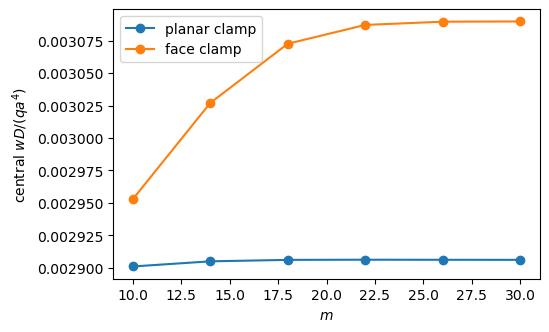

In [5]:
model = 'plate_tsdt_donnell'
ms = [10, 14, 18, 22, 26, 30]
conv = {'planar clamp': [], 'face clamp': []}
for m in ms:
    s = plate(model, m=m)
    for x in (0., A):
        face_clamp(s, x)
    conv['face clamp'].append(fields(s, static(s), A/2, B/2)['w'][0]*D/(Q*A**4))
    s = plate(model, m=m)
    clamp_by_flags(s, 'x1')
    clamp_by_flags(s, 'x2')
    conv['planar clamp'].append(fields(s, static(s), A/2, B/2)['w'][0]*D/(Q*A**4))
for i, m in enumerate(ms):
    print('m = %2d: w D/(q a^4), planar clamp %.6f, face clamp %.6f'
          % (m, conv['planar clamp'][i], conv['face clamp'][i]))
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for name, vals in conv.items():
    ax.plot(ms, vals, 'o-', label=name)
ax.set_xlabel('$m$')
ax.set_ylabel('central $w D/(q a^4)$')
ax.legend()
plt.show()

With $m = 26$ the face clamp is converged within about $10^{-3}$ and the planar clamp within $10^{-4}$. The three supports of the thick plate, $h/a = 0.1$:

In [6]:
model = 'plate_tsdt_donnell'
face = plate(model)
for x in (0., A):
    face_clamp(face, x)
c_face = static(face)

planar = plate(model)
clamp_by_flags(planar, 'x1')
clamp_by_flags(planar, 'x2')
c_planar = static(planar)

u_three = plate(model)
for x in (0., A):
    face_clamp(u_three, x)
    u_three.add_distr_pd_fixed_x(x, ku=1., kv=1., funcu=lambda y: 0.,
                                 funcv=lambda y: 0., z=H/4)
c_three = static(u_three)

ss = plate(model)
simple_support(ss)
c_ss = static(ss)

f3, fp = fields(u_three, c_three, xs, ys), fields(planar, c_planar, xs, ys)
print('u = 0 at three coordinates vs planar clamp: largest difference %.1e '
      'of the largest w' % (max(np.abs(f3[k] - fp[k]).max() for k in FIELDS)
                            / np.abs(fp['w']).max()))
center = {}
for name, s, c in (('planar clamp', planar, c_planar),
                   ('face clamp', face, c_face),
                   ('simple support', ss, c_ss)):
    center[name] = fields(s, c, A/2, B/2)['w'][0]*D/(Q*A**4)
    print('%-15s w D/(q a^4) = %.6f' % (name, center[name]))
clpt = {'planar clamp': thin['plate_clpt_donnell', 'planar clamp'][0],
        'face clamp': thin['plate_clpt_donnell', 'planar clamp'][0],
        'simple support': thin['plate_clpt_donnell', 'simple support'][0]}
for name in center:
    print('%-15s increase over the thin plate (CLPT): %+.1f%%'
          % (name, 100*(center[name]/clpt[name] - 1)))
results_table([
    ('planar clamp, $w D/(q a^4)$', center['planar clamp'], 1/384,
     'thin plate, cylindrical bending, Timoshenko and Woinowsky-Krieger (1959), Eq. (18)'),
    ('face clamp, $w D/(q a^4)$', center['face clamp'], 1/384,
     'thin plate, cylindrical bending, Timoshenko and Woinowsky-Krieger (1959), Eq. (18)'),
    ('simple support, $w D/(q a^4)$', center['simple support'], 0.01309,
     'thin plate, Timoshenko and Woinowsky-Krieger (1959), Table 47'),
])

u = 0 at three coordinates vs planar clamp: largest difference 0.0e+00 of the largest w
planar clamp    w D/(q a^4) = 0.002906
face clamp      w D/(q a^4) = 0.003090
simple support  w D/(q a^4) = 0.013459
planar clamp    increase over the thin plate (CLPT): +13.5%
face clamp      increase over the thin plate (CLPT): +20.7%
simple support  increase over the thin plate (CLPT): +2.8%


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| planar clamp, $w D/(q a^4)$ | 0.00290625 | 0.00260417 | +1.16e-01 | thin plate, cylindrical bending, Timoshenko and Woinowsky-Krieger (1959), Eq. (18) |
| face clamp, $w D/(q a^4)$ | 0.00308958 | 0.00260417 | +1.86e-01 | thin plate, cylindrical bending, Timoshenko and Woinowsky-Krieger (1959), Eq. (18) |
| simple support, $w D/(q a^4)$ | 0.013459 | 0.01309 | +2.82e-02 | thin plate, Timoshenko and Woinowsky-Krieger (1959), Table 47 |

The references are thin-plate values: the differences are the effect of the transverse shear deformation at $h/a = 0.1$, which the TSDT includes. The shear deflection adds to the bending deflection a part that grows as $(h/a)^2$ relative to it. It is about 3% for the simple support but about 13% for the planar clamp, because the clamp reduces the bending deflection about five times while the shear deflection is of the same order for both supports; the warping of the face clamp adds about 6% more. No published solution of this thick plate with free edges was found for a direct comparison.

The deflection along the center line $y = b/2$, and the in-plane displacement $u(z)$ through the thickness at the clamped edge $x = 0$, at $y = b/2$. With the face clamp $u$ vanishes at the faces and not inside, while the planar clamp keeps the whole section fixed:

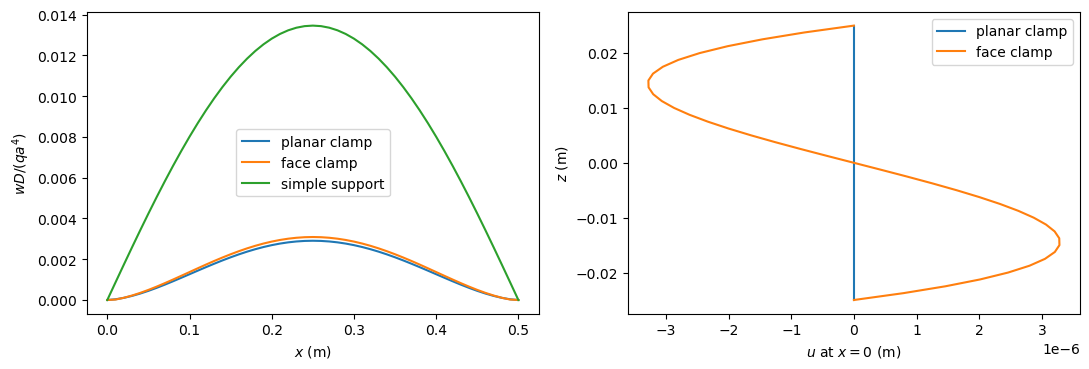

In [7]:
xl = np.linspace(0, A, 51)
zs = np.linspace(-H/2, H/2, 41)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, s, c in (('planar clamp', planar, c_planar),
                   ('face clamp', face, c_face),
                   ('simple support', ss, c_ss)):
    w = fields(s, c, xl, np.full_like(xl, B/2))['w']
    axes[0].plot(xl, w*D/(Q*A**4), label=name)
    if name != 'simple support':
        f = fields(s, c, [0.], [B/2])
        axes[1].plot([uv_at(s, f, z)[0][0] for z in zs], zs, label=name)
axes[0].set_xlabel('$x$ (m)')
axes[0].set_ylabel('$w D/(q a^4)$')
axes[0].legend()
axes[1].set_xlabel('$u$ at $x = 0$ (m)')
axes[1].set_ylabel('$z$ (m)')
axes[1].legend()
fig.tight_layout()
plt.show()

At the face-clamped edge the section warps with $\phi_x = w_{,x}/2$, so that $\gamma_{xz} = 3\phi_x$ there, and

$$
u(z) = \frac{w_{,x}}{2}\, z \left(1 - \frac{4 z^2}{h^2}\right),
$$

which vanishes at $z = \pm h/2$. The value at $z = h/4$ is compared with this expression:

In [8]:
f = fields(face, c_face, np.zeros(11), np.linspace(0, B, 11))
u_h4 = uv_at(face, f, H/4)[0]
ref_h4 = f['gxz']/3*H/4*(1 - 4*(H/4)**2/H**2)
print('largest |u| at the faces: %.1e m, largest |u| at z = h/4: %.3e m'
      % (np.abs(uv_at(face, f, H/2)[0]).max(), np.abs(u_h4).max()))
print('largest |gxz - 3 phix|: %.1e' % np.abs(f['gxz'] - 3*f['phix']).max())
i = np.argmax(np.abs(u_h4))
results_table([('$u(h/4)$ at $x = 0$, $y = %.2f$ (m)' % np.linspace(0, B, 11)[i],
                u_h4[i], ref_h4[i],
                r'$(w_{,x}/2) z (1 - 4z^2/h^2)$, with $\gamma_{xz} = 3\phi_x$')])

largest |u| at the faces: 4.4e-16 m, largest |u| at z = h/4: 4.078e-06 m
largest |gxz - 3 phix|: 5.3e-14


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| $u(h/4)$ at $x = 0$, $y = 0.50$ (m) | -4.07829e-06 | -4.07829e-06 | -3.35e-12 | $(w_{,x}/2) z (1 - 4z^2/h^2)$, with $\gamma_{xz} = 3\phi_x$ |

## Independence of the reference surface

Both clamps are defined by the physical section. The deflections do not depend on the offset $d$ of the reference surface:

In [9]:
res = {}
for offset in (0., 0.3*H, 0.5*H):
    s = plate(model, offset)
    for x in (0., A):
        face_clamp(s, x)
    t = plate(model, offset)
    clamp_by_flags(t, 'x1')
    clamp_by_flags(t, 'x2')
    res[offset] = (fields(s, static(s), xs, ys)['w'],
                   fields(t, static(t), xs, ys)['w'])
for offset in (0.3*H, 0.5*H):
    print('offset %.3f m: largest relative change of w, face clamp %.1e, '
          'planar clamp %.1e' % (offset,
          *[np.abs(res[offset][i] - res[0.][i]).max()/np.abs(res[0.][i]).max()
            for i in (0, 1)]))

offset 0.015 m: largest relative change of w, face clamp 1.2e-11, planar clamp 1.7e-11
offset 0.025 m: largest relative change of w, face clamp 1.5e-11, planar clamp 3.7e-11


## Penalty method

With the penalty method, the springs of the prescribed displacements, `fkCld_xcte`, are given the same `z` and added to the stiffness matrix by the user. With a stiffness of $10^4 E$, the face clamp at $x = 0$ and a shortening $\delta = 10^{-5}$ m of both faces at $x = a$ give the solution of the null-space method:

In [10]:
delta = 1e-5


def build(k, offset=0.):
    s = plate(model, offset)
    face_clamp(s, 0., k=k)
    for z in (offset - H/2, offset + H/2):
        s.add_distr_pd_fixed_x(A, ku=k, kv=k, funcu=lambda y: -delta,
                               funcv=lambda y: 0., z=z)
    s.add_distr_pd_fixed_x(A, kw=k, funcw=lambda y: 0.)
    return s


s = build(1.)
c = static(s)
k = 1e4*E
p = build(k)
md = MultiDomain([p], conn=[])
size = md.get_size()
kCp = 0
for x in (0., A):
    for z in (-H/2, H/2):
        kCp = kCp + fkCld_xcte(k, k, 0., p, x, size, 0, 0, z=z)
    kCp = kCp + fkCld_xcte(0., 0., k, p, x, size, 0, 0)
K = md.calc_kC() + finalize_symmetric_matrix(kCp)
cp = solve(K, md.calc_fext(), silent=True)
f, fpen = fields(s, c, xs, ys), fields(p, cp, xs, ys)
for key in ('u', 'w'):
    print('largest difference of %s, penalty vs null-space: %.1e of the '
          'largest' % (key, np.abs(fpen[key] - f[key]).max()
                       / np.abs(f[key]).max()))
fa = fields(s, c, np.full(5, A), np.linspace(0, B, 5))
u_face = uv_at(s, fa, H/2)[0]
results_table([('$u$ of the face $z = h/2$ at $x = a$ (m)', u_face.mean(),
                -delta, 'prescribed value')])

largest difference of u, penalty vs null-space: 1.0e-05 of the largest
largest difference of w, penalty vs null-space: 1.3e-05 of the largest


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| $u$ of the face $z = h/2$ at $x = a$ (m) | -1e-05 | -1e-05 | +2.25e-11 | prescribed value |

## References

1. J. N. Reddy, "A simple higher-order theory for laminated composite plates". Journal of Applied Mechanics, 51(4):745-752, 1984. https://doi.org/10.1115/1.3167719.
2. S. Timoshenko and S. Woinowsky-Krieger, "Theory of Plates and Shells". 2nd ed., McGraw-Hill, New York, 1959.